# Notebook 06 — Analisis Jarak Spasial Centroid terhadap Rumah Pompa Aktif

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Tujuan Notebook Ini
1. Menghitung **jarak lurus Euclidean (meter)** pada CRS proyeksi seragam **UTM Zona 49S (`EPSG:32749`)** dari masing-masing **31 centroid kandidat awal** terhadap **seluruh 71 rumah pompa Operasional Aktif** Kota Surabaya (lintas batas rayon diizinkan dan dicatat eksplisit).
2. Mengidentifikasi rumah pompa aktif terdekat untuk tiap centroid (`id_pompa`, `nama_stasiun_pompa`, `rayon_pematusan`, dan jarak dalam meter) serta memeriksa secara transparan potensi *tie* jarak akibat duplikat koordinat (`PMP-013` & `PMP-014` *P.A Bozem Moro Krembangan I*).
3. Menyajikan analisis sekunder **terpisah** terhadap **12 lokasi rumah pompa Pengembangan Baru** sebagai informasi konteks pendukung tanpa mencampurnya ke analisis jarak utama.
4. Membuat tabel hasil per rayon & peringkat jarak (`outputs/tables/`), peta garis penghubung (*spider map*) & grafik distribusi jarak (`outputs/figures/`), serta mengekspor layer GeoJSON `EPSG:4326` siap pakai untuk WebGIS Tahap 7 (`outputs/geojson/`).

> **Batasan Metodologis Penting:** Jarak yang dihitung adalah **jarak lurus Euclidean (*straight-line distance*)** dalam meter, **bukan** jarak tempuh sepanjang jaringan saluran drainase, bukan radius layanan hidraulis (tidak menggunakan buffer 1,5 km maupun *snapping*), dan bukan bukti ketidakterlayanan atau kelayakan pembangunan fisik.

## 1. Setup Path, Import Modul `src/spatial_analysis.py`, dan Memuat Data Terproses

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.spatial_analysis import (
    compute_nearest_active_pump_distances,
    compute_development_context_distances,
    export_analysis_and_webgis_outputs,
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"
GEOJSON_DIR = PROJECT_ROOT / "outputs" / "geojson"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 120

gdf_centroids = gpd.read_file(PROCESSED_DIR / "centroid_kmeans_utm49s.gpkg")
gdf_pompa_aktif = gpd.read_file(PROCESSED_DIR / "rumah_pompa_aktif_utm49s.gpkg")
gdf_pompa_kembang = gpd.read_file(PROCESSED_DIR / "rumah_pompa_pengembangan_utm49s.gpkg")
gdf_rayon = gpd.read_file(PROCESSED_DIR / "rayon_pematusan_utm49s.gpkg").sort_values("id_rayon").reset_index(drop=True)
gdf_kmeans = gpd.read_file(PROCESSED_DIR / "saluran_kmeans_utm49s.gpkg")

df_dbscan_summary = pd.read_csv(TAB_DIR / "03_dbscan_ringkasan_per_rayon.csv")
df_eval_rayon = pd.read_csv(TAB_DIR / "05_evaluasi_kmeans_per_rayon.csv")

print(f"Centroid kandidat awal       : {len(gdf_centroids)} titik | CRS: {gdf_centroids.crs}")
print(f"Rumah pompa Operasional Aktif: {len(gdf_pompa_aktif)} entri ({gdf_pompa_aktif[['easting','northing']].drop_duplicates().shape[0]} koordinat unik) | CRS: {gdf_pompa_aktif.crs}")
print(f"Rumah pompa Pengembangan Baru: {len(gdf_pompa_kembang)} entri (layer pendukung terpisah) | CRS: {gdf_pompa_kembang.crs}")

Centroid kandidat awal       : 31 titik | CRS: EPSG:32749
Rumah pompa Operasional Aktif: 71 entri (70 koordinat unik) | CRS: EPSG:32749
Rumah pompa Pengembangan Baru: 12 entri (layer pendukung terpisah) | CRS: EPSG:32749


## 2. Analisis Jarak Utama: 31 Centroid terhadap 71 Rumah Pompa Operasional Aktif (`EPSG:32749`)
Untuk tiap centroid, kita menghitung jarak Euclidean ke seluruh 71 rumah pompa aktif kota Surabaya, mencatat rumah pompa terdekat, memeriksa status `Sama Rayon` vs `Lintas Rayon`, dan mengecek apakah terjadi *tie* koordinat (`PMP-013` & `PMP-014`).

In [2]:
gdf_centroid_dist, gdf_links, df_rayon_summary = compute_nearest_active_pump_distances(
    gdf_centroids=gdf_centroids,
    gdf_pompa_aktif=gdf_pompa_aktif,
)

print("=== RINGKASAN JARAK LURUS EUCLIDEAN KE RUMAH POMPA AKTIF TERDEKAT PER RAYON ===")
display(df_rayon_summary)

print("\n=== CEK TRANSPARAN: CENTROID DENGAN TIE KOORDINAT (PMP-013 / PMP-014) ===")
tie_df = gdf_centroid_dist[gdf_centroid_dist["is_tie_pompa_aktif"]]
if len(tie_df) == 0:
    print("Tidak ada centroid yang rumah pompa aktif terdekatnya mengalami tie koordinat (PMP-013/PMP-014).")
else:
    display(tie_df[[
        "centroid_id", "nama_rayon", "id_pompa_aktif_terdekat",
        "nama_pompa_aktif_terdekat", "jarak_pompa_aktif_terdekat_m", "catatan_tie_pompa_aktif"
    ]])

print("\n=== CEK CENTROID DENGAN RUMAH POMPA AKTIF TERDEKAT LINTAS RAYON ===")
lintas_df = gdf_centroid_dist[gdf_centroid_dist["status_lintas_rayon"] == "Lintas Rayon"]
print(f"Jumlah centroid lintas rayon: {len(lintas_df)} dari {len(gdf_centroid_dist)} centroid")
if len(lintas_df) > 0:
    display(lintas_df[[
        "centroid_id", "nama_rayon", "id_pompa_aktif_terdekat",
        "nama_pompa_aktif_terdekat", "rayon_pompa_aktif_terdekat",
        "jarak_pompa_aktif_terdekat_m", "nama_pompa_aktif_serayon", "jarak_pompa_aktif_serayon_m"
    ]])

=== RINGKASAN JARAK LURUS EUCLIDEAN KE RUMAH POMPA AKTIF TERDEKAT PER RAYON ===


,id_rayon,nama_rayon,jumlah_centroid,jumlah_pompa_aktif_di_rayon,jarak_min_m,centroid_terdekat,jarak_median_m,jarak_rerata_m,jarak_max_m,centroid_terjauh,jumlah_lintas_rayon,jumlah_tie_koordinat
0,RYN-01,Rayon Benowo,5,2,1307.51,RYN-01-C01,3514.88,3603.33,5365.84,RYN-01-C03,2,0
1,RYN-02,Rayon Tandes,4,5,550.35,RYN-02-C04,1409.22,1387.13,2179.72,RYN-02-C01,2,0
2,RYN-03,Rayon Wiyung,5,5,155.00,RYN-03-C04,1183.06,1972.72,6408.19,RYN-03-C01,1,0
3,RYN-04,Rayon Jambangan,5,11,447.58,RYN-04-C03,799.83,747.17,1167.55,RYN-04-C02,0,0
4,RYN-05,Rayon Rungkut,4,15,468.44,RYN-05-C03,936.07,982.75,1590.41,RYN-05-C02,0,0
5,RYN-06,Rayon Genteng,4,14,263.06,RYN-06-C02,683.08,676.74,1077.74,RYN-06-C03,0,0
6,RYN-07,Rayon Gubeng,4,19,566.52,RYN-07-C02,1250.89,1318.09,2204.06,RYN-07-C03,0,0
7,ALL,Seluruh 7 Rayon (31 Centroid),31,71,155.00,RYN-03-C04,1077.74,1583.06,6408.19,RYN-03-C01,5,0



=== CEK TRANSPARAN: CENTROID DENGAN TIE KOORDINAT (PMP-013 / PMP-014) ===
Tidak ada centroid yang rumah pompa aktif terdekatnya mengalami tie koordinat (PMP-013/PMP-014).

=== CEK CENTROID DENGAN RUMAH POMPA AKTIF TERDEKAT LINTAS RAYON ===
Jumlah centroid lintas rayon: 5 dari 31 centroid


,centroid_id,nama_rayon,id_pompa_aktif_terdekat,nama_pompa_aktif_terdekat,rayon_pompa_aktif_terdekat,jarak_pompa_aktif_terdekat_m,nama_pompa_aktif_serayon,jarak_pompa_aktif_serayon_m
2,RYN-01-C03,Rayon Benowo,PMP-046,P.A Balong 1,Rayon Tandes,5365.84,P.A Kandangan,6811.25
4,RYN-01-C05,Rayon Benowo,PMP-046,P.A Balong 1,Rayon Tandes,3514.88,P.A Kandangan,4198.28
7,RYN-02-C03,Rayon Tandes,PMP-071,P.A Bukit Barisan,Rayon Genteng,1804.14,PA. Underpass,2053.93
8,RYN-02-C04,Rayon Tandes,PMP-009,P.A Asem Jaya,Rayon Genteng,550.35,P.A Bozem Moro Krembangan I,2634.08
9,RYN-03-C01,Rayon Wiyung,PMP-046,P.A Balong 1,Rayon Tandes,6408.19,P.A WIYUNG,8702.48


## 3. Tabel Lengkap 31 Centroid Diurutkan dari Jarak Terjauh ke Terdekat (Analisis Utama)

In [3]:
cols_tabel = [
    "peringkat_jarak_terjauh", "centroid_id", "nama_rayon", "jumlah_titik",
    "easting", "northing", "longitude", "latitude",
    "id_pompa_aktif_terdekat", "nama_pompa_aktif_terdekat", "rayon_pompa_aktif_terdekat",
    "jarak_pompa_aktif_terdekat_m", "status_lintas_rayon", "catatan_tie_pompa_aktif"
]
display(gdf_centroid_dist.sort_values("peringkat_jarak_terjauh")[cols_tabel].reset_index(drop=True))

,peringkat_jarak_terjauh,centroid_id,nama_rayon,jumlah_titik,easting,northing,longitude,latitude,id_pompa_aktif_terdekat,nama_pompa_aktif_terdekat,rayon_pompa_aktif_terdekat,jarak_pompa_aktif_terdekat_m,status_lintas_rayon,catatan_tie_pompa_aktif
0,1,RYN-03-C01,Rayon Wiyung,4,679881.00,9194614.40,112.629392,-7.283249,PMP-046,P.A Balong 1,Rayon Tandes,6408.19,Lintas Rayon,
1,2,RYN-01-C03,Rayon Benowo,68,680668.65,9195381.73,112.636500,-7.276285,PMP-046,P.A Balong 1,Rayon Tandes,5365.84,Lintas Rayon,
2,3,RYN-01-C04,Rayon Benowo,310,681009.39,9197970.60,112.639501,-7.252865,PMP-010,P.A Kandangan,Rayon Benowo,4481.54,Sama Rayon,
3,4,RYN-01-C05,Rayon Benowo,370,682060.21,9197601.30,112.649028,-7.256170,PMP-046,P.A Balong 1,Rayon Tandes,3514.88,Lintas Rayon,
4,5,RYN-01-C02,Rayon Benowo,359,678182.74,9199269.04,112.613863,-7.241216,PMP-011,P.A Sumber Rejo,Rayon Benowo,3346.86,Sama Rayon,
5,6,RYN-07-C03,Rayon Gubeng,2650,695348.54,9200873.48,112.769235,-7.226132,PMP-076,P.A Bulak,Rayon Gubeng,2204.06,Sama Rayon,
6,7,RYN-02-C01,Rayon Tandes,1340,683568.81,9196701.97,112.662718,-7.264252,PMP-046,P.A Balong 1,Rayon Tandes,2179.72,Sama Rayon,
7,8,RYN-02-C03,Rayon Tandes,173,688756.03,9196111.21,112.709709,-7.269419,PMP-071,P.A Bukit Barisan,Rayon Genteng,1804.14,Lintas Rayon,
8,9,RYN-05-C02,Rayon Rungkut,620,696226.66,9189228.72,112.777600,-7.331386,PMP-053,P.A UPN,Rayon Rungkut,1590.41,Sama Rayon,
9,10,RYN-07-C01,Rayon Gubeng,2081,693644.88,9198623.87,112.753889,-7.246531,PMP-069,P.A Undaan,Rayon Gubeng,1533.96,Sama Rayon,


## 4. Analisis Sekunder Terpisah: Konteks 12 Rumah Pompa Pengembangan Baru
Sesuai metodologi, 12 lokasi berstatus `Pengembangan Baru` **tidak dicampur** ke perhitungan utama 71 rumah pompa aktif. Tabel terpisah berikut hanya memberikan informasi kontekstual mengenai centroid mana yang secara geografis lebih dekat ke salah satu dari 12 lokasi pengembangan dibanding rumah pompa aktif terdekatnya.

In [4]:
df_dev_context = compute_development_context_distances(
    gdf_centroid_dist=gdf_centroid_dist,
    gdf_pompa_pengembangan=gdf_pompa_kembang,
)

closer_dev = df_dev_context[df_dev_context["pengembangan_lebih_dekat_dari_aktif"]].sort_values(
    "selisih_jarak_aktif_minus_kembang_m", ascending=False
)
print(f"Jumlah centroid yang lebih dekat ke lokasi Pengembangan Baru dibanding Aktif: {len(closer_dev)} / {len(df_dev_context)}")
display(closer_dev)

Jumlah centroid yang lebih dekat ke lokasi Pengembangan Baru dibanding Aktif: 10 / 31


,centroid_id,nama_rayon,jarak_pompa_aktif_terdekat_m,id_pompa_aktif_terdekat,id_pengembangan_terdekat,nama_pengembangan_terdekat,rayon_pengembangan_terdekat,jarak_pengembangan_terdekat_m,pengembangan_lebih_dekat_dari_aktif,selisih_jarak_aktif_minus_kembang_m
4,RYN-01-C05,Rayon Benowo,3514.88,PMP-046,PMP-080,Rumah Pompa Update #80 (Baru),Rayon Tandes,1004.04,True,2510.84
2,RYN-01-C03,Rayon Benowo,5365.84,PMP-046,PMP-080,Rumah Pompa Update #80 (Baru),Rayon Tandes,2986.91,True,2378.93
3,RYN-01-C04,Rayon Benowo,4481.54,PMP-010,PMP-080,Rumah Pompa Update #80 (Baru),Rayon Tandes,2117.75,True,2363.79
9,RYN-03-C01,Rayon Wiyung,6408.19,PMP-046,PMP-080,Rumah Pompa Update #80 (Baru),Rayon Tandes,4082.75,True,2325.44
5,RYN-02-C01,Rayon Tandes,2179.72,PMP-046,PMP-080,Rumah Pompa Update #80 (Baru),Rayon Tandes,788.71,True,1391.01
20,RYN-05-C02,Rayon Rungkut,1590.41,PMP-053,PMP-077,Rumah Pompa Update #77 (Baru),Rayon Rungkut,963.66,True,626.75
27,RYN-07-C01,Rayon Gubeng,1533.96,PMP-069,PMP-066,Rumah Pompa Update #66 (Baru),Rayon Gubeng,997.45,True,536.51
15,RYN-04-C02,Rayon Jambangan,1167.55,PMP-031,PMP-083,Rumah Pompa Update #83 (Baru),Rayon Jambangan,869.56,True,297.99
29,RYN-07-C03,Rayon Gubeng,2204.06,PMP-076,PMP-066,Rumah Pompa Update #66 (Baru),Rayon Gubeng,2006.78,True,197.28
14,RYN-04-C01,Rayon Jambangan,503.28,PMP-072,PMP-078,Rumah Pompa Update #78 (Baru),Rayon Jambangan,485.49,True,17.79


## 5. Visualisasi 1 — Peta Garis Penghubung (*Spider Map*) 31 Centroid ke Rumah Pompa Aktif Terdekat
Menampilkan 7 rayon pematusan, 31 centroid kandidat awal (berwarna menurut jarak ke pompa aktif terdekat), 31 garis penghubung Euclidean (garis tegas = Sama Rayon, garis putus-putus = Lintas Rayon), 71 rumah pompa Operasional Aktif (segitiga merah), dan 12 lokasi Pengembangan Baru sebagai layer terpisah (kotak ungu).

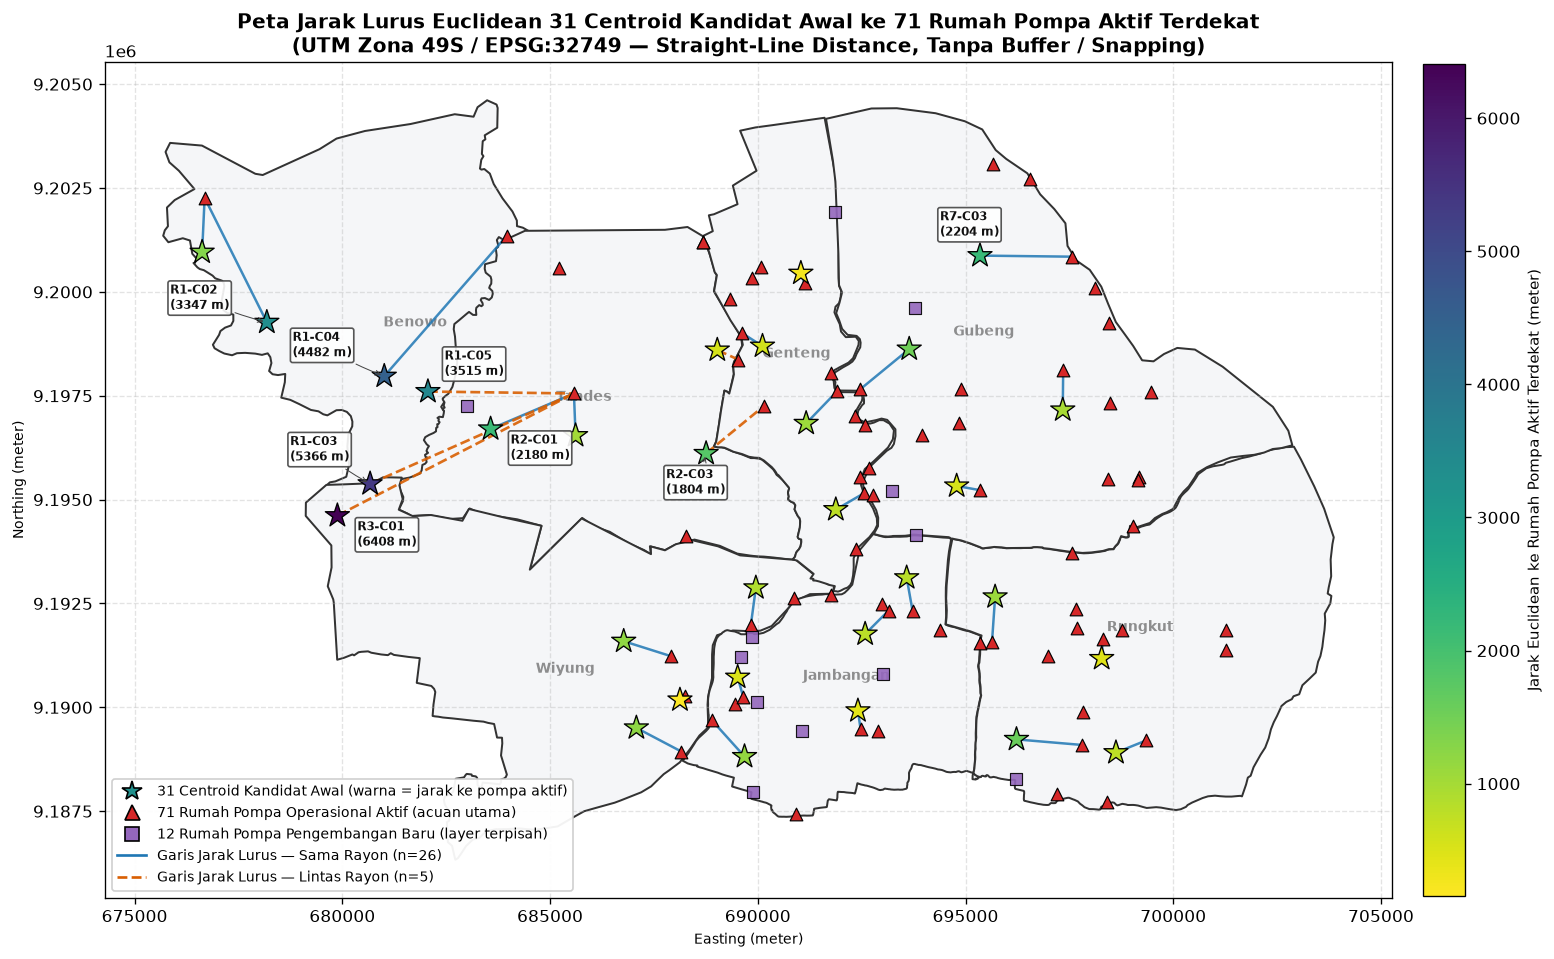

Peta spider disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\06_peta_spider_jarak_pompa.png


In [5]:
fig, ax = plt.subplots(figsize=(14, 10.5))

# 7 poligon rayon
gdf_rayon.plot(ax=ax, facecolor="#F5F6F8", edgecolor="#333333", linewidth=1.2, zorder=1)
for _, rrow in gdf_rayon.iterrows():
    pt = rrow.geometry.representative_point()
    tx, ty = pt.x, pt.y
    if "Benowo" in rrow["nama_rayon"]:
        tx += 1400
        ty -= 400
    ax.text(
        tx, ty, rrow["nama_rayon"].replace("Rayon ", ""),
        fontsize=8.5, fontweight="bold", ha="center", va="center", color="#555555", alpha=0.65, zorder=2
    )

# Garis penghubung (spider links)
links_same = gdf_links[gdf_links["status_lintas_rayon"] == "Sama Rayon"]
links_cross = gdf_links[gdf_links["status_lintas_rayon"] == "Lintas Rayon"]
if len(links_same) > 0:
    links_same.plot(ax=ax, color="#1F77B4", linewidth=1.5, linestyle="-", alpha=0.85, zorder=3)
if len(links_cross) > 0:
    links_cross.plot(ax=ax, color="#D95F02", linewidth=1.6, linestyle="--", alpha=0.90, zorder=3)

# Rumah pompa: 71 Aktif & 12 Pengembangan (layer terpisah)
gdf_pompa_aktif.plot(ax=ax, color="#D62728", edgecolor="black", marker="^", markersize=58, linewidth=0.7, zorder=4)
gdf_pompa_kembang.plot(ax=ax, color="#9467BD", edgecolor="black", marker="s", markersize=46, linewidth=0.7, alpha=0.9, zorder=4)

# 31 Centroid diwarnai berdasarkan jarak ke rumah pompa aktif terdekat
sc = ax.scatter(
    gdf_centroid_dist["easting"],
    gdf_centroid_dist["northing"],
    c=gdf_centroid_dist["jarak_pompa_aktif_terdekat_m"],
    cmap="viridis_r",
    marker="*",
    s=230,
    edgecolor="black",
    linewidth=0.8,
    zorder=6,
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.68, pad=0.02)
cbar.set_label("Jarak Euclidean ke Rumah Pompa Aktif Terdekat (meter)", fontsize=9)

# Custom offsets per centroid agar posisi setiap label optimal & tidak tabrakan
custom_offsets = {
    "RYN-03-C01": (12, -18),     # Wiyung micro-subcluster (ke kanan bawah bintangnya)
    "RYN-01-C03": (-48, 14),     # Benowo selatan (ke kiri atas bintangnya)
    "RYN-01-C04": (-55, 12),     # Benowo tengah-barat (ke kiri bintangnya)
    "RYN-01-C05": (10, 10),      # Benowo tengah-timur (ke kanan atas bintangnya)
    "RYN-01-C02": (-58, 8),      # Benowo barat laut (ke kiri bintangnya)
    "RYN-07-C03": (-24, 12),     # Gubeng utara (ke kiri atas bintangnya)
    "RYN-02-C01": (12, -18),     # Tandes barat (ke kanan bawah bintangnya)
    "RYN-02-C03": (-24, -24),    # Tandes selatan (ke kiri bawah bintangnya)
}

# Label ringkas pada 8 centroid terjauh (dan RYN-03-C01)
top_annotate = gdf_centroid_dist.nsmallest(8, "peringkat_jarak_terjauh")
for _, crow in top_annotate.iterrows():
    cid = crow["centroid_id"]
    offset = custom_offsets.get(cid, (8, 8))
    has_arrow = abs(offset[0]) > 40 or abs(offset[1]) > 20
    ax.annotate(
        f"{crow['centroid_id'].replace('RYN-0', 'R')}\n({crow['jarak_pompa_aktif_terdekat_m']:.0f} m)",
        xy=(crow["easting"], crow["northing"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=7.3,
        fontweight="bold",
        color="#111111",
        bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="#444444", alpha=0.90),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.05", color="#444444", lw=0.6) if has_arrow else None,
        zorder=7,
    )

handles_sp = [
    Line2D([0], [0], marker="*", color="w", label="31 Centroid Kandidat Awal (warna = jarak ke pompa aktif)", markerfacecolor="#21908C", markeredgecolor="black", markersize=12),
    Line2D([0], [0], marker="^", color="w", label="71 Rumah Pompa Operasional Aktif (acuan utama)", markerfacecolor="#D62728", markeredgecolor="black", markersize=9),
    Line2D([0], [0], marker="s", color="w", label="12 Rumah Pompa Pengembangan Baru (layer terpisah)", markerfacecolor="#9467BD", markeredgecolor="black", markersize=8),
    Line2D([0], [0], color="#1F77B4", lw=1.6, ls="-", label=f"Garis Jarak Lurus — Sama Rayon (n={len(links_same)})"),
    Line2D([0], [0], color="#D95F02", lw=1.6, ls="--", label=f"Garis Jarak Lurus — Lintas Rayon (n={len(links_cross)})"),
]
ax.legend(handles=handles_sp, loc="lower left", frameon=True, facecolor="white", framealpha=0.94, fontsize=8.5)
ax.set_title("Peta Jarak Lurus Euclidean 31 Centroid Kandidat Awal ke 71 Rumah Pompa Aktif Terdekat\n(UTM Zona 49S / EPSG:32749 — Straight-Line Distance, Tanpa Buffer / Snapping)", fontsize=12, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal")

fig_spider = FIG_DIR / "06_peta_spider_jarak_pompa.png"
plt.tight_layout()
plt.savefig(fig_spider, dpi=200, bbox_inches="tight")
plt.show()
print(f"Peta spider disimpan ke: {fig_spider}")

## 6. Visualisasi 2 — Peringkat Jarak 31 Centroid & Distribusi Jarak per Rayon

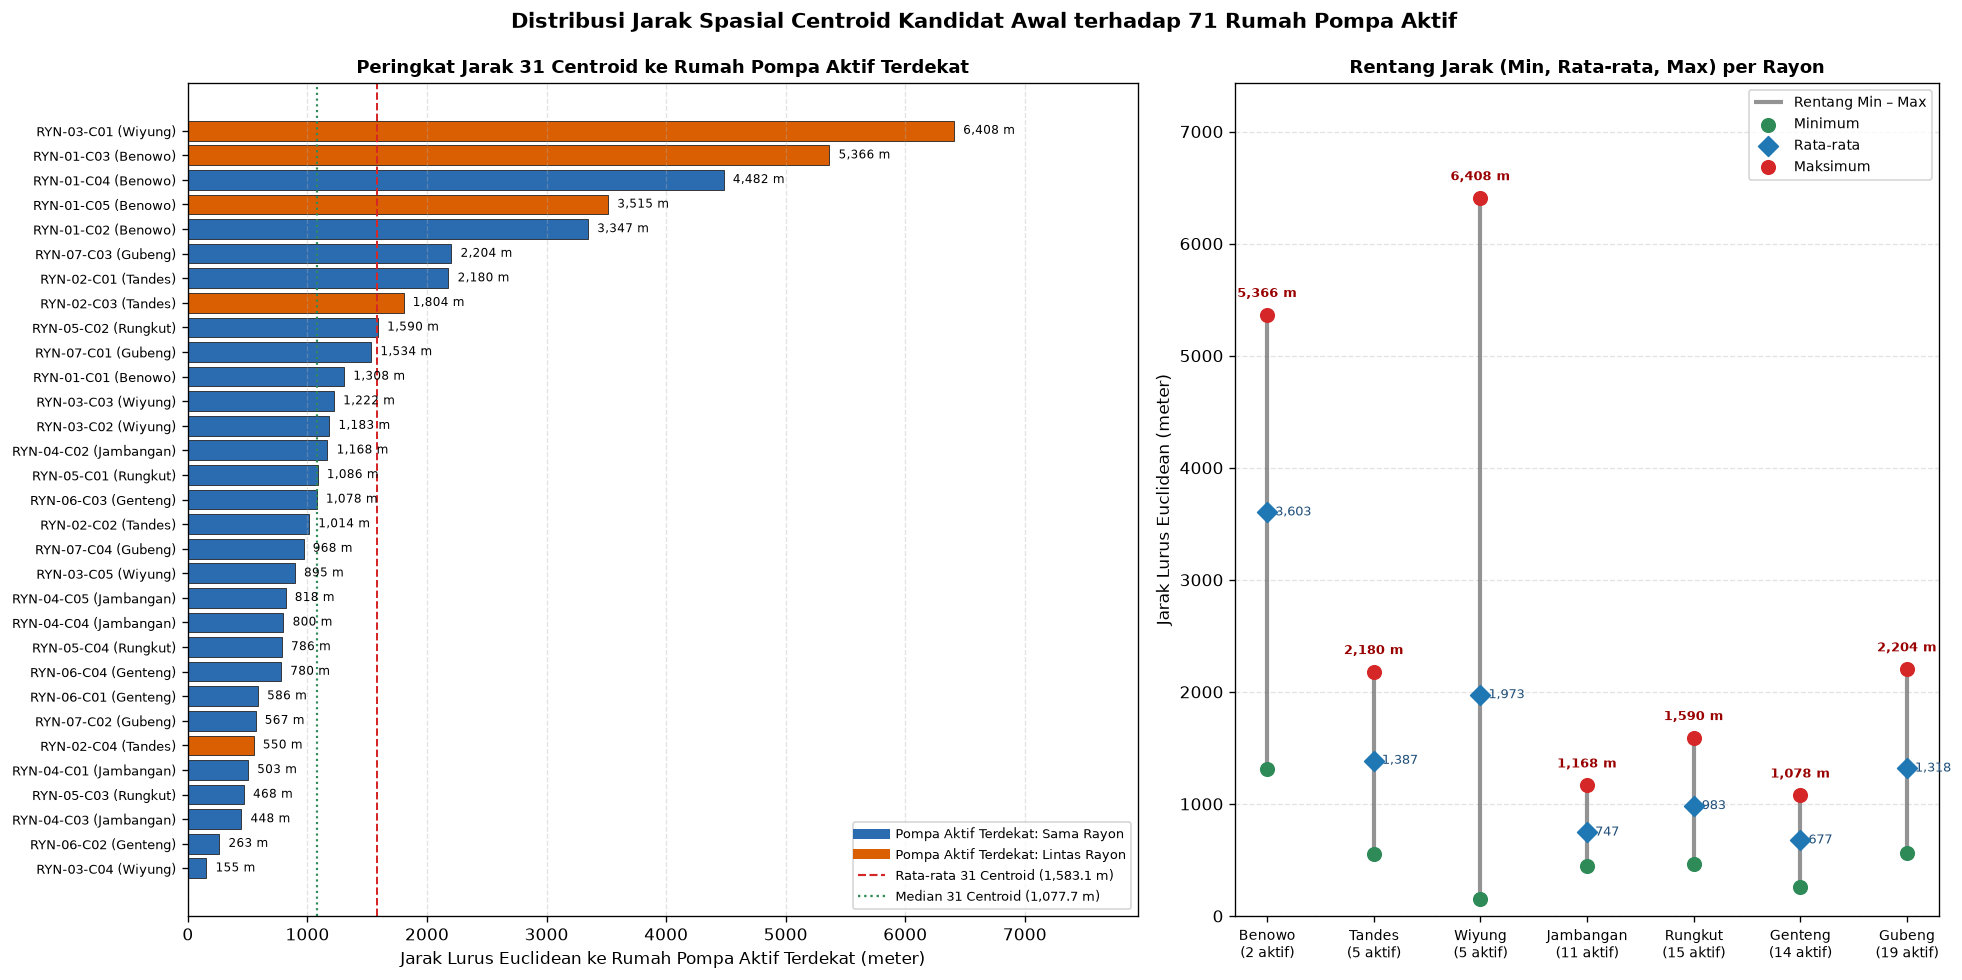

Grafik distribusi jarak disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\06_distribusi_jarak_centroid_pompa.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 8.2), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Panel Kiri: Peringkat seluruh 31 centroid (terjauh di atas)
ax1 = axes[0]
df_rank = gdf_centroid_dist.sort_values("jarak_pompa_aktif_terdekat_m", ascending=True).reset_index(drop=True)
colors_bar = [
    "#D95F02" if st == "Lintas Rayon" else "#2B6CB0"
    for st in df_rank["status_lintas_rayon"]
]
y_pos = np.arange(len(df_rank))
bars = ax1.barh(y_pos, df_rank["jarak_pompa_aktif_terdekat_m"], color=colors_bar, edgecolor="#222222", linewidth=0.5)

labels_y = [
    f"{r['centroid_id']} ({r['nama_rayon'].replace('Rayon ', '')})"
    for _, r in df_rank.iterrows()
]
ax1.set_yticks(y_pos)
ax1.set_yticklabels(labels_y, fontsize=7.8)
mean_all = float(df_rank["jarak_pompa_aktif_terdekat_m"].mean())
med_all = float(df_rank["jarak_pompa_aktif_terdekat_m"].median())
ax1.axvline(mean_all, color="#D62728", linestyle="--", linewidth=1.2, label=f"Rata-rata ({mean_all:.0f} m)")
ax1.axvline(med_all, color="#2E8B57", linestyle=":", linewidth=1.3, label=f"Median ({med_all:.0f} m)")

max_d = float(df_rank["jarak_pompa_aktif_terdekat_m"].max())
ax1.set_xlim(0, max_d * 1.24)
for b, pnama in zip(bars, df_rank["nama_pompa_aktif_terdekat"]):
    w = b.get_width()
    ax1.text(w + max_d * 0.012, b.get_y() + b.get_height()/2, f"{w:,.0f} m", va="center", fontsize=7.4)

leg1 = [
    Line2D([0], [0], color="#2B6CB0", lw=6, label="Pompa Aktif Terdekat: Sama Rayon"),
    Line2D([0], [0], color="#D95F02", lw=6, label="Pompa Aktif Terdekat: Lintas Rayon"),
    Line2D([0], [0], color="#D62728", lw=1.3, ls="--", label=f"Rata-rata 31 Centroid ({mean_all:,.1f} m)"),
    Line2D([0], [0], color="#2E8B57", lw=1.4, ls=":", label=f"Median 31 Centroid ({med_all:,.1f} m)"),
]
ax1.legend(handles=leg1, loc="lower right", fontsize=8.0, frameon=True)
ax1.set_xlabel("Jarak Lurus Euclidean ke Rumah Pompa Aktif Terdekat (meter)")
ax1.set_title("Peringkat Jarak 31 Centroid ke Rumah Pompa Aktif Terdekat", fontsize=11, fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.35)

# Panel Kanan: Ringkasan Min, Mean, Max Jarak per Rayon
ax2 = axes[1]
df_rs = df_rayon_summary[df_rayon_summary["id_rayon"] != "ALL"].copy()
r_labels = [f"{r['nama_rayon'].replace('Rayon ', '')}\n({int(r['jumlah_pompa_aktif_di_rayon'])} aktif)" for _, r in df_rs.iterrows()]
x_r = np.arange(len(df_rs))

# Plot rentang min-max + titik rata-rata & median
ax2.vlines(x_r, df_rs["jarak_min_m"], df_rs["jarak_max_m"], color="#666666", linewidth=2.5, alpha=0.7, label="Rentang Min – Max")
ax2.scatter(x_r, df_rs["jarak_min_m"], color="#2E8B57", s=65, zorder=4, label="Minimum")
ax2.scatter(x_r, df_rs["jarak_rerata_m"], color="#1F77B4", marker="D", s=70, zorder=5, label="Rata-rata")
ax2.scatter(x_r, df_rs["jarak_max_m"], color="#D62728", s=65, zorder=4, label="Maksimum")

for i_r, row in df_rs.reset_index(drop=True).iterrows():
    ax2.text(i_r, row["jarak_max_m"] + 130, f"{row['jarak_max_m']:,.0f} m", ha="center", va="bottom", fontsize=7.8, color="#990000", fontweight="bold")
    ax2.text(i_r, row["jarak_rerata_m"], f"  {row['jarak_rerata_m']:,.0f}", ha="left", va="center", fontsize=7.6, color="#1F4E79")

ax2.set_xticks(x_r)
ax2.set_xticklabels(r_labels, fontsize=8.5)
ax2.set_ylim(0, df_rs["jarak_max_m"].max() * 1.16)
ax2.set_ylabel("Jarak Lurus Euclidean (meter)")
ax2.set_title("Rentang Jarak (Min, Rata-rata, Max) per Rayon", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", fontsize=8.5, frameon=True)
ax2.grid(axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Distribusi Jarak Spasial Centroid Kandidat Awal terhadap 71 Rumah Pompa Aktif", fontsize=12.5, fontweight="bold", y=0.99)
plt.tight_layout()
fig_dist = FIG_DIR / "06_distribusi_jarak_centroid_pompa.png"
plt.savefig(fig_dist, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik distribusi jarak disimpan ke: {fig_dist}")

## 7. Validasi Akhir & Ekspor Output Tahap 6 (`data/processed/`, `outputs/tables/`, `outputs/geojson/`)
Sekaligus mengekspor 6 layer GeoJSON dalam `EPSG:4326` ke `outputs/geojson/` yang siap langsung dikonsumsi oleh WebGIS Streamlit + Folium pada Tahap 7.

In [7]:
# Validasi otomatis Tahap 6
assert len(gdf_centroid_dist) == 31
assert len(gdf_links) == 31
assert (gdf_centroid_dist["jarak_pompa_aktif_terdekat_m"] > 0).all()
assert gdf_centroid_dist.crs.to_epsg() == 32749
assert gdf_links.crs.to_epsg() == 32749

saved = export_analysis_and_webgis_outputs(
    processed_dir=PROCESSED_DIR,
    tables_dir=TAB_DIR,
    geojson_dir=GEOJSON_DIR,
    gdf_centroid_dist=gdf_centroid_dist,
    gdf_links=gdf_links,
    df_rayon_summary=df_rayon_summary,
    df_dev_context=df_dev_context,
    gdf_rayon_utm=gdf_rayon,
    gdf_pompa_aktif_utm=gdf_pompa_aktif,
    gdf_pompa_pengembangan_utm=gdf_pompa_kembang,
    gdf_kmeans_utm=gdf_kmeans,
    df_dbscan_summary=df_dbscan_summary,
    df_eval_rayon=df_eval_rayon,
)

print("VALIDASI TAHAP 6 LULUS SEMUA ASSERTION!")
print("Seluruh output & layer GeoJSON WebGIS berhasil disimpan:")
for k, p in saved.items():
    print(f"  - {k:32s}: {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size:,} bytes)")

VALIDASI TAHAP 6 LULUS SEMUA ASSERTION!
Seluruh output & layer GeoJSON WebGIS berhasil disimpan:
  - centroid_jarak_gpkg             : data\processed\centroid_jarak_pompa_utm49s.gpkg (114,688 bytes)
  - garis_jarak_gpkg                : data\processed\garis_jarak_centroid_pompa_utm49s.gpkg (106,496 bytes)
  - tabel_jarak_centroid_csv        : outputs\tables\06_jarak_centroid_ke_pompa_aktif.csv (8,499 bytes)
  - tabel_ringkasan_jarak_csv       : outputs\tables\06_ringkasan_jarak_per_rayon.csv (869 bytes)
  - tabel_konteks_pengembangan_csv  : outputs\tables\06_konteks_sekunder_pompa_pengembangan.csv (3,820 bytes)
  - geojson_rayon                   : outputs\geojson\7_rayon_pematusan_ringkasan.geojson (79,700 bytes)
  - geojson_centroid                : outputs\geojson\31_centroid_kandidat_jarak.geojson (34,963 bytes)
  - geojson_links                   : outputs\geojson\31_garis_jarak_pompa_aktif.geojson (14,719 bytes)
  - geojson_pompa_aktif             : outputs\geojson\71_rumah_pompa